In [1]:
import time, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

DATASET = "FashionMNIST"
EPOCHS = 6
BATCH = 128
LR = 1e-3
SEED = 0
RUN_EXTRA = True

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device, "| zbiór:", DATASET)

PyTorch: 2.14.1+cpu | urządzenie: cpu | zbiór: FashionMNIST


In [2]:
if DATASET == "CIFAR10":
    IN_CH, IMG = 3, 32
    tf = transforms.Compose([transforms.ToTensor(),
                             transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])
    ds_cls = torchvision.datasets.CIFAR10
else:
    IN_CH, IMG = 1, 28
    tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
    ds_cls = torchvision.datasets.FashionMNIST

train_ds = ds_cls("./data", train=True,  download=True, transform=tf)
test_ds  = ds_cls("./data", train=False, download=True, transform=tf)
train_eval_dl = DataLoader(train_ds, batch_size=512, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=512, shuffle=False)
print("train:", len(train_ds), "| test:", len(test_ds), "| wejście:", (IN_CH, IMG, IMG))

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 272kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.34MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.6MB/s]

train: 60000 | test: 10000 | wejście: (1, 28, 28)


In [3]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, pool="max", n_blocks=2, head="gap", in_ch=IN_CH, img=IMG):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            if pool == "max":
                layers.append(nn.MaxPool2d(2))
            elif pool == "avg":
                layers.append(nn.AvgPool2d(2))
            elif pool == "max3":
                layers.append(nn.MaxPool2d(3, stride=2, padding=1))
            elif pool == "stride":
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1), nn.BatchNorm2d(cout), nn.ReLU()]
            return nn.Sequential(*layers)
        chans = [in_ch, 32, 64, 128][:n_blocks + 1]
        self.features = nn.Sequential(*[block(chans[i], chans[i + 1]) for i in range(n_blocks)])
        with torch.no_grad():
            c, h, w = self.features(torch.zeros(1, in_ch, img, img)).shape[1:]
        self.fmap = (c, h, w)
        if head == "gap":
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, n_classes))
        else:
            self.head = nn.Sequential(nn.Flatten(), nn.Linear(c * h * w, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

def count(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

for p in ["max", "avg", "stride"]:
    m = CNN(pool=p)
    print(f"pool={p:6} | parametry {count(m):>7,} | głowica {count(m.head):>6,} | mapa przed GAP {list(m.fmap)}")

pool=max    | parametry  19,658 | głowica    650 | mapa przed GAP [64, 7, 7]
pool=avg    | parametry  19,658 | głowica    650 | mapa przed GAP [64, 7, 7]
pool=stride | parametry  66,026 | głowica    650 | mapa przed GAP [64, 7, 7]


In [4]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def evaluate(model, dl):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item(); total += yb.numel()
    return correct / total

def run(name, **kw):
    set_seed(SEED)
    model = CNN(**kw).to(device)
    g = torch.Generator().manual_seed(SEED)
    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, generator=g)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    tr, te = [], []
    t0 = time.time()
    for e in range(EPOCHS):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        tr.append(evaluate(model, train_eval_dl)); te.append(evaluate(model, test_dl))
        print(f"  [{name}] epoka {e+1}/{EPOCHS} | train {tr[-1]*100:.2f}% | test {te[-1]*100:.2f}%")
    res = dict(name=name, params=count(model), head_params=count(model.head), fmap=model.fmap,
               train=tr, test=te, time=time.time() - t0)
    print(f"{name}: test {te[-1]*100:.2f}% | parametry {res['params']:,} | czas {res['time']:.0f} s\n")
    return res

In [5]:
def table(results):
    print(f"{'wariant':22} | {'parametry':>9} | {'głowica':>7} | {'mapa [C,H,W]':>13} | {'test (ost.)':>11} | {'train (ost.)':>12} | {'train-test':>10} | {'max test*':>9}")
    print("-" * 115)
    for r in results:
        gap = (r["train"][-1] - r["test"][-1]) * 100
        print(f"{r['name']:22} | {r['params']:>9,} | {r['head_params']:>7,} | {str(list(r['fmap'])):>13} | "
              f"{r['test'][-1]*100:>10.2f}% | {r['train'][-1]*100:>11.2f}% | {gap:>9.2f}pp | {max(r['test'])*100:>8.2f}%")
    print("* max test = najlepsza epoka wybrana na zbiorze testowym (tylko informacyjnie, nie jest to wynik końcowy)")

def plot(results, title):
    ep = range(1, EPOCHS + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for r in results:
        line, = axes[0].plot(ep, [a*100 for a in r["train"]], "o-", label=r["name"])
        axes[1].plot(ep, [a*100 for a in r["test"]], "o-", color=line.get_color(), label=r["name"])
    for ax, t in zip(axes, ["trening", "test"]):
        ax.set_title(f"{title} — accuracy ({t})"); ax.set_xlabel("epoka"); ax.set_ylabel("accuracy [%]")
        ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

  [max 2x2] epoka 1/6 | train 72.30% | test 71.99%
  [max 2x2] epoka 2/6 | train 79.29% | test 78.64%
  [max 2x2] epoka 3/6 | train 82.32% | test 81.53%
  [max 2x2] epoka 4/6 | train 83.12% | test 81.92%
  [max 2x2] epoka 5/6 | train 79.41% | test 79.02%
  [max 2x2] epoka 6/6 | train 81.38% | test 81.03%
max 2x2: test 81.03% | parametry 19,658 | czas 1064 s

  [avg 2x2] epoka 1/6 | train 67.25% | test 67.09%
  [avg 2x2] epoka 2/6 | train 74.56% | test 74.50%
  [avg 2x2] epoka 3/6 | train 77.27% | test 76.48%
  [avg 2x2] epoka 4/6 | train 80.58% | test 80.26%
  [avg 2x2] epoka 5/6 | train 80.27% | test 79.72%
  [avg 2x2] epoka 6/6 | train 80.67% | test 79.83%
avg 2x2: test 79.83% | parametry 19,658 | czas 988 s

  [conv 3x3 stride 2] epoka 1/6 | train 83.71% | test 82.86%
  [conv 3x3 stride 2] epoka 2/6 | train 88.14% | test 86.94%
  [conv 3x3 stride 2] epoka 3/6 | train 89.09% | test 87.79%
  [conv 3x3 stride 2] epoka 4/6 | train 90.68% | test 88.66%
  [conv 3x3 stride 2] epoka 5/6 | t

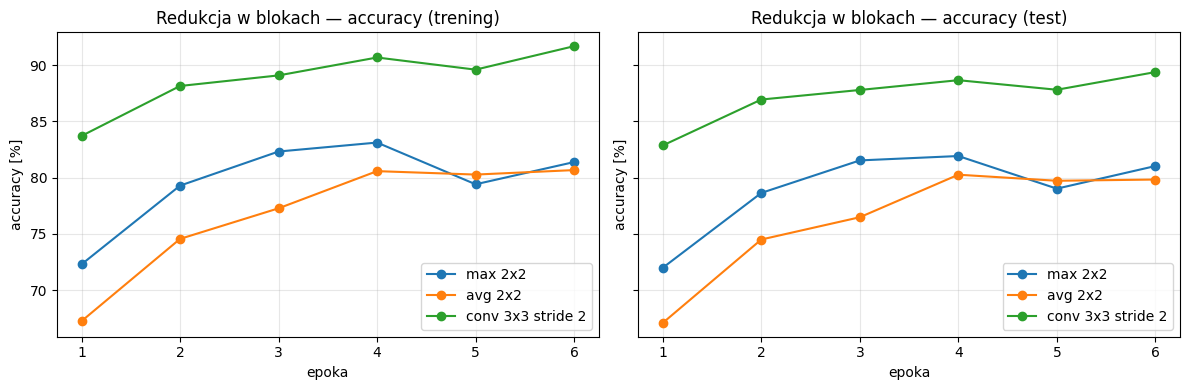

In [6]:
main = [run("max 2x2", pool="max"),
        run("avg 2x2", pool="avg"),
        run("conv 3x3 stride 2", pool="stride")]
table(main)
plot(main, "Redukcja w blokach")

  [max 3x3 s2 p1] epoka 1/6 | train 77.73% | test 76.99%
  [max 3x3 s2 p1] epoka 2/6 | train 79.62% | test 78.84%
  [max 3x3 s2 p1] epoka 3/6 | train 82.68% | test 81.62%
  [max 3x3 s2 p1] epoka 4/6 | train 82.37% | test 81.39%
  [max 3x3 s2 p1] epoka 5/6 | train 78.85% | test 78.24%
  [max 3x3 s2 p1] epoka 6/6 | train 82.11% | test 81.27%
max 3x3 s2 p1: test 81.27% | parametry 19,658 | czas 1062 s

  [max 2x2, 3 bloki] epoka 1/6 | train 87.91% | test 86.29%
  [max 2x2, 3 bloki] epoka 2/6 | train 90.81% | test 89.22%
  [max 2x2, 3 bloki] epoka 3/6 | train 91.97% | test 89.96%
  [max 2x2, 3 bloki] epoka 4/6 | train 91.33% | test 89.35%
  [max 2x2, 3 bloki] epoka 5/6 | train 91.93% | test 89.83%
  [max 2x2, 3 bloki] epoka 6/6 | train 92.38% | test 89.81%
max 2x2, 3 bloki: test 89.81% | parametry 94,410 | czas 1161 s

  [max 3x3, 3 bloki] epoka 1/6 | train 87.84% | test 86.44%
  [max 3x3, 3 bloki] epoka 2/6 | train 89.36% | test 88.11%
  [max 3x3, 3 bloki] epoka 3/6 | train 90.22% | test 

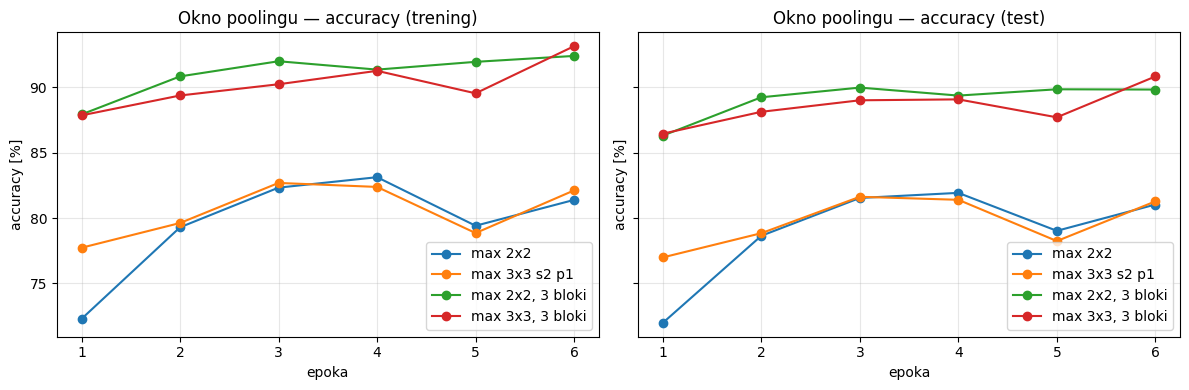

In [7]:
if RUN_EXTRA:
    win = [main[0], run("max 3x3 s2 p1", pool="max3"),
           run("max 2x2, 3 bloki", pool="max", n_blocks=3),
           run("max 3x3, 3 bloki", pool="max3", n_blocks=3)]
    table(win)
    plot(win, "Okno poolingu")

  [max 2x2, Flatten] epoka 1/6 | train 90.91% | test 89.39%
  [max 2x2, Flatten] epoka 2/6 | train 91.34% | test 89.19%
  [max 2x2, Flatten] epoka 3/6 | train 92.70% | test 90.58%
  [max 2x2, Flatten] epoka 4/6 | train 92.71% | test 90.38%
  [max 2x2, Flatten] epoka 5/6 | train 93.11% | test 90.58%
  [max 2x2, Flatten] epoka 6/6 | train 93.58% | test 90.52%
max 2x2, Flatten: test 90.52% | parametry 50,378 | czas 913 s

wariant                | parametry | głowica |  mapa [C,H,W] | test (ost.) | train (ost.) | train-test | max test*
-------------------------------------------------------------------------------------------------------------------
max 2x2                |    19,658 |     650 |    [64, 7, 7] |      81.03% |       81.38% |      0.35pp |    81.92%
max 2x2, Flatten       |    50,378 |  31,370 |    [64, 7, 7] |      90.52% |       93.58% |      3.06pp |    90.58%
* max test = najlepsza epoka wybrana na zbiorze testowym (tylko informacyjnie, nie jest to wynik końcowy)


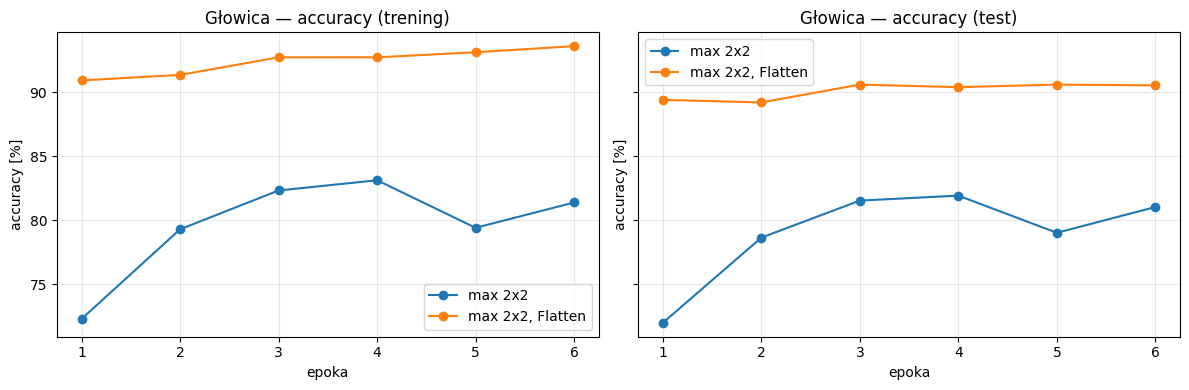

In [8]:
if RUN_EXTRA:
    heads = [main[0], run("max 2x2, Flatten", pool="max", head="flatten")]
    table(heads)
    plot(heads, "Głowica")

  [max 2x2, 1 blok] epoka 1/6 | train 44.39% | test 45.07%
  [max 2x2, 1 blok] epoka 2/6 | train 51.05% | test 50.81%
  [max 2x2, 1 blok] epoka 3/6 | train 55.56% | test 55.15%
  [max 2x2, 1 blok] epoka 4/6 | train 56.67% | test 56.58%
  [max 2x2, 1 blok] epoka 5/6 | train 59.03% | test 58.64%
  [max 2x2, 1 blok] epoka 6/6 | train 60.51% | test 60.41%
max 2x2, 1 blok: test 60.41% | parametry 714 | czas 532 s

wariant                | parametry | głowica |  mapa [C,H,W] | test (ost.) | train (ost.) | train-test | max test*
-------------------------------------------------------------------------------------------------------------------
max 2x2, 1 blok        |       714 |     330 |  [32, 14, 14] |      60.41% |       60.51% |      0.10pp |    60.41%
max 2x2                |    19,658 |     650 |    [64, 7, 7] |      81.03% |       81.38% |      0.35pp |    81.92%
max 2x2, 3 bloki       |    94,410 |   1,290 |   [128, 3, 3] |      89.81% |       92.38% |      2.57pp |    89.96%
* max te

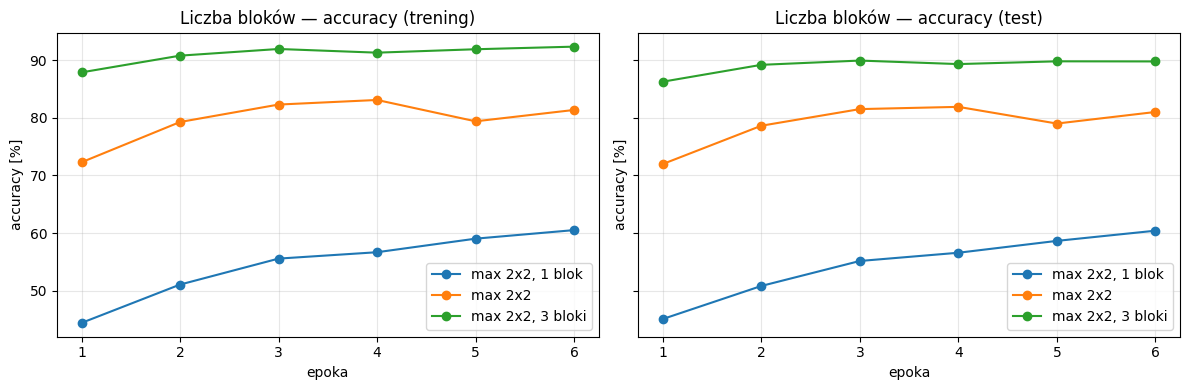

In [9]:
if RUN_EXTRA:
    blocks = [run("max 2x2, 1 blok", pool="max", n_blocks=1), main[0], win[2]]
    table(blocks)
    plot(blocks, "Liczba bloków")